In [1]:
# LIBRERIE

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("a_cmi_internet.csv")
legenda = pd.read_csv("a_data_dictionary.csv")

# Stagioni enceoded winter=0, spring=1, summer=2, autumn=3

df['Fitness_Endurance-Tempo_totale'] = df['Fitness_Endurance-Time_Sec'] + \
    (df['Fitness_Endurance-Time_Mins']*60)

In [3]:
# Colonne just to check
col_categoriche = df.select_dtypes(include=["object"]).columns
col_numeriche = df.select_dtypes(
    include=["int64", "float64"]).columns
col_quantitative = df.select_dtypes(
    include=["int64", "float64"]).columns.drop("id")

col_da_escludere = [
    "FGC-FGC_CU_Zone", "FGC-FGC_GSND_Zone", "FGC-FGC_GSD_Zone",
    "FGC-FGC_PU_Zone", "FGC-FGC_SRL_Zone", "FGC-FGC_SRR_Zone",
    "FGC-FGC_TL_Zone"
]

col_non_bin = col_quantitative.difference(col_da_escludere)

categoriche = df[col_categoriche]
stagioni = {"Winter": 0, "Spring": 1, "Summer": 2, "Fall": 3}
tutto_numerico = df.copy()
tutto_numerico[col_categoriche] = tutto_numerico[col_categoriche].replace(
    stagioni)
correlazione = tutto_numerico.corr()

/var/folders/dx/gml1dzlj4hv40xclhd6scg5r0000gn/T/ipykernel_49259/1928229715.py:19: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  tutto_numerico[col_categoriche] = tutto_numerico[col_categoriche].replace(


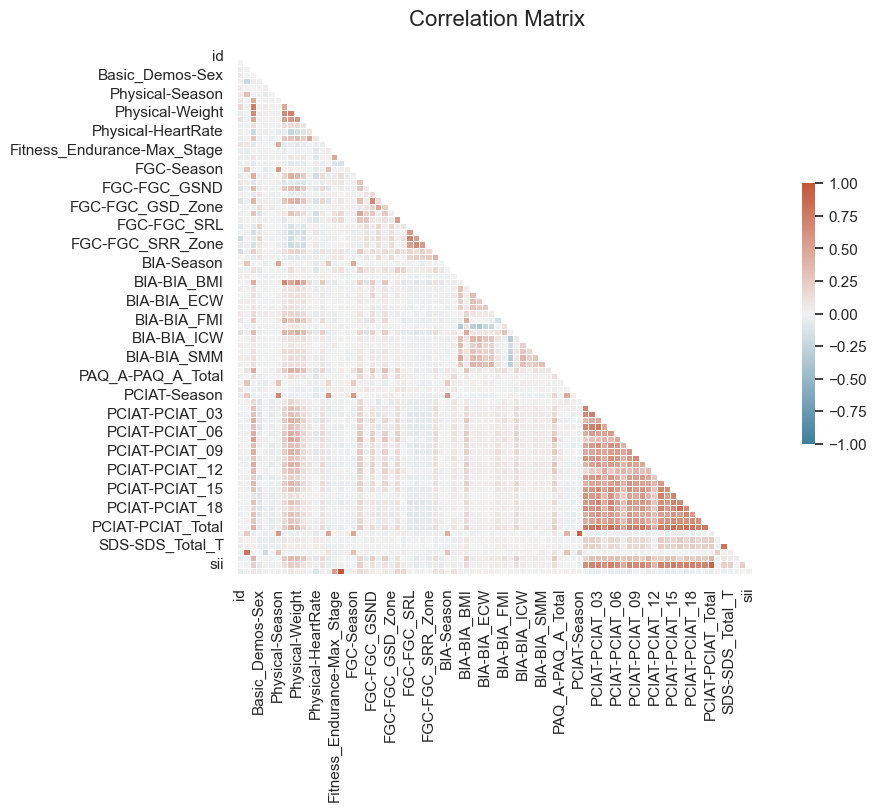

In [4]:
sns.set_theme(style="white")


def plot_professional_matrix(corr_matrix, title="Correlation Matrix"):
    # Creazione di una singola figura
    fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)

    # Maschera per nascondere la parte superiore (triangolo)
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    # Palette divergente professionale (es. Rosso-Blu)
    cmap = sns.diverging_palette(230, 20, as_cmap=True)

    # Generazione della heatmap
    sns.heatmap(corr_matrix,
                mask=mask,
                cmap=cmap,
                vmax=1, vmin=-1, center=0,
                square=True,
                linewidths=.5,
                cbar_kws={"shrink": .5},
                annot=False,             # Impostare a True per mostrare i numeri
                fmt=".2f",               # Formato arrotondamento decimali
                ax=ax)

    # Impostazione del titolo
    ax.set_title(title, fontsize=16, pad=20)

    plt.show()


plot_professional_matrix(correlazione)

In [5]:
# Fuori Scala

# CGAS-CGAS_Score
df["CGAS-CGAS_Score"] = df["CGAS-CGAS_Score"].mask(lambda x: x > 100, np.nan)

# Physical BMI
df["FGC-FGC_GSD"].value_counts()

FGC-FGC_GSD
21.20    1450
18.75    1365
19.00     109
18.50      89
24.75      62
         ... 
12.10       1
38.80       1
6.50        1
32.20       1
53.75       1
Name: count, Length: 452, dtype: int64

In [6]:
# Rimuovere 18+
# 0 = nan da lista
# paq Da arrotondare

df = df[df["Basic_Demos-Age"] <= 18]

df['PAQ_A-PAQ_A_Total'] = df['PAQ_A-PAQ_A_Total'].clip(lower=1)
df['PAQ_C-PAQ_C_Total'] = df['PAQ_C-PAQ_C_Total'].clip(lower=1)

colonne_zeri = ['Physical-BMI', 'Physical-Weight',
                'Physical-Diastolic_BP', 'Physical-Systolic_BP']
df[colonne_zeri] = df[colonne_zeri].mask(lambda x: x == 0, np.nan)


# train
train_set, test_set = train_test_split(
    df, test_size=0.3, stratify=df["sii"], random_state=222)

train_set = train_set.copy()
test_set = test_set.copy()

In [7]:
# imputazione

imputer = KNNImputer(n_neighbors=76)  # np.sqrt(5823)
train_imputed = pd.DataFrame(
    imputer.fit_transform(train_set[col_non_bin]),
    columns=col_non_bin,
    index=train_set.index)

test_imputed = pd.DataFrame(
    imputer.transform(test_set[col_non_bin]),
    columns=col_non_bin,
    index=test_set.index)

In [8]:
train_imputed["Fitness_Endurance-Max_Stage"].value_counts()

Fitness_Endurance-Max_Stage
5.000000     2661
4.500000      512
6.000000      305
4.000000      291
4.973684      139
             ... 
26.500000       1
5.289474        1
5.592105        1
4.717105        1
25.000000       1
Name: count, Length: 124, dtype: int64

In [9]:
train_set["Fitness_Endurance-Max_Stage"].value_counts()

Fitness_Endurance-Max_Stage
5.0     2184
4.5      512
6.0      305
4.0      291
5.5      132
3.0       77
7.0       73
2.0       51
3.5       36
2.5       33
1.5       19
6.5       15
1.0       11
7.5        7
8.0        6
8.5        4
9.0        3
9.5        3
10.0       2
12.0       2
21.0       1
22.0       1
17.5       1
26.0       1
26.5       1
18.5       1
19.5       1
25.0       1
Name: count, dtype: int64

In [10]:
'''from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor
import pandas as pd

rf_estimator = RandomForestRegressor(random_state=222)
imputer_rf = IterativeImputer(estimator=rf_estimator, random_state=222, max_iter=5)

train_imputed_rf = pd.DataFrame(
    imputer_rf.fit_transform(train_set[col_non_bin]), 
    columns=col_non_bin, 
    index=train_set.index
)

test_imputed_rf = pd.DataFrame(
    imputer_rf.transform(test_set[col_non_bin]), 
    columns=col_non_bin, 
    index=test_set.index
)'''

'from sklearn.experimental import enable_iterative_imputer\nfrom sklearn.impute import IterativeImputer\nfrom sklearn.ensemble import RandomForestRegressor\nimport pandas as pd\n\nrf_estimator = RandomForestRegressor(random_state=222)\nimputer_rf = IterativeImputer(estimator=rf_estimator, random_state=222, max_iter=5)\n\ntrain_imputed_rf = pd.DataFrame(\n    imputer_rf.fit_transform(train_set[col_non_bin]), \n    columns=col_non_bin, \n    index=train_set.index\n)\n\ntest_imputed_rf = pd.DataFrame(\n    imputer_rf.transform(test_set[col_non_bin]), \n    columns=col_non_bin, \n    index=test_set.index\n)'

In [11]:
# Salvataggio dati in CSV

train_imputed.to_csv("train_imputed.csv", index=True)
test_imputed.to_csv("test_imputed.csv", index=True)